# Build the event-study panel

```
Build the analysis-ready event-study panel and write it to processed_data/.

Run this once, after the NTL_processing scripts. Results_paper.ipynb then
loads the panel it writes and needs none of the heavy raw inputs below.

Outputs
-------
processed_data/event_study_panel.dta   137 markets x 8 years (2018-2025), with
processed_data/event_study_panel.csv   the outcome variables, the three
                                       baseline market characteristics, the two
                                       time-varying controls, the district
                                       cluster id, and the two NTL sample flags
                                       (always-lit n=52, ever-lit n=107).

Inputs
------
processed_data/ntl_bnr_periodic137_8years.csv   (from NTL_processing/06_)
document/Repo_09042026/data/...                 market activity, ACLED, NDVI,
                                                population, district shapefile
```

In [38]:
import os
import re
import sys

import numpy as np
import pandas as pd

# fiona >= 1.10 no longer imports this submodule eagerly, but geopandas 0.13
# reaches for fiona.path when opening a file. Import it before geopandas.
import fiona
import fiona.path  # noqa: F401
import geopandas as gpd

sys.path.insert(0, os.path.join(os.getcwd(), "NTL_processing"))  # run from code_paper/
from config import DATA, PROCESSED, REPO_DATA  # noqa: E402

In [39]:
YEARS = list(range(2018, 2026))
TARGET = "activity_area_norm2020"

# Markets whose trading days are known but missing from the registry file.
SUPPLIED_DAYS = {
    'lon62_5018lat34_2416': {1},
    'lon63_7803lat35_731':  {2, 3, 6},
    'lon69_3316lat35_0459': {6},
    'lon70_3678lat34_8331': {4},
}
HERAT_MKT = 'lon62_5018lat34_2416'

# Conflict channels counted in the district-year death rate.
IED = {'Remote explosive/landmine/IED'}
GATHER = {'Air/drone strike', 'Shelling/artillery/missile attack', 'Attack',
          'Suicide bomb', 'Grenade'}
CLASH = {'Armed clash'}
CHANNELS = IED | GATHER | CLASH

In [40]:
def market_year_activity(d):
    """One activity value per market-year, same cleaning and cascade as
    mai_series but truncated at the market (not averaged across markets)."""
    s = d.copy()
    s = s[s['mktDay'] == 1].copy()
    s['DataWithIssue'] = np.where(~s[TARGET].between(-5, 300), 1, 0)
    s['DataWithIssue'] = np.where(s[TARGET].isnull(), np.nan, s['DataWithIssue'])
    s = s[s['DataWithIssue'] == 0].copy(deep=True)
    s[TARGET] = s.groupby(['date', 'mktID'])[TARGET].transform('mean')
    s = s.drop_duplicates(subset=['date', 'mktID'])
    return (s.groupby(['mktID', 'year', 'quarter', 'month', 'week'])[TARGET].mean().reset_index()
             .groupby(['mktID', 'year', 'quarter', 'month'])[TARGET].mean().reset_index()
             .groupby(['mktID', 'year', 'quarter'])[TARGET].mean().reset_index()
             .groupby(['mktID', 'year'])[TARGET].mean().unstack())

df_mkt = pd.read_csv(os.path.join(PROCESSED, "market_images.csv"))
df_mkt = df_mkt[~df_mkt['year'].isin([2017, 2026])].copy(deep=True)

mm = market_year_activity(df_mkt)

mm_long = (mm.reset_index()
             .melt(id_vars='mktID', var_name='year', value_name='activity'))
mm_long
display(mm_long['activity'].describe())

count    1084.000000
mean      119.920147
std        38.264356
min        18.960566
25%        98.381023
50%       113.697639
75%       137.618236
max       297.491575
Name: activity, dtype: float64

In [41]:
def _daystr(days):
    return '{' + ', '.join(f"'{d}'" for d in sorted(days)) + '}'


def build_panel():
    """Reimplements common.panel(include_herat=True) without the matplotlib
    import that common.py otherwise requires."""
    p = pd.read_csv(os.path.join(REPO_DATA, 'derived', 'periodict_act.csv'), low_memory=False)
    p = p[['mktID','weekday', 'marketlat', 'marketlon',   'admLvl1','un_region','marketDays','wp_SUM',
           'open_2018', 'open_2019', 'open_2020', 'open_2021', 'open_2022',
           'open_2023', 'open_2024', 'open_2025']].drop_duplicates(subset=['mktID'])

    p = df_mkt[['image_id', 'mktID','activity_area_norm2020','year', 'month', 'quarter', 'week','date','mktDay']].merge(p, on=['mktID'], how='left', indicator=True)
    
    fill = p.mktID.map({k: _daystr(v) for k, v in SUPPLIED_DAYS.items()})
    p['marketDays'] = p.marketDays.where(p.marketDays.notna(), fill)
    raw = pd.read_csv(os.path.join(REPO_DATA, 'afg_periodic_markets_20260213',
                                   'forAFG_paper_activity_all.csv'), low_memory=False)
    raw = raw.rename(columns={'Location': 'mktID'})
    h = raw[raw.mktID == HERAT_MKT].copy()
    d = pd.to_datetime(h.date, format='mixed')
    h['year'] = d.dt.year
    h['month'] = d.dt.month
    h['quarter'] = (h.month - 1) // 3 + 1
    h['week'] = d.dt.isocalendar().week.astype(int)
    h['weekday'] = (d.dt.dayofweek + 1) % 7
    hd = SUPPLIED_DAYS[HERAT_MKT]
    h['mktDay'] = h.weekday.isin(hd).astype(int)
    h = h[h.mktDay == 1]
    h['marketDays'] = _daystr(hd)
    for c in p.columns:
        if c not in h.columns:
            h[c] = np.nan
    h['mktID'] = HERAT_MKT
    for c, v in [('admLvl1', 'Hirat'), ('un_region', 'West'), ('un_region_small', 'West')]:
        h[c] = v
    aux = pd.concat([p, h[p.columns]], ignore_index=True)
    aux = aux[~aux['weekday'].isna()].copy(deep=True)
    return aux

In [42]:
def haversine(lat1, lon1, lat2, lon2):
    a1, b1, a2, b2 = map(np.radians, [lat1, lon1, lat2, lon2])
    return 2 * 6371 * np.arcsin(np.sqrt(
        np.sin((a2 - a1) / 2) ** 2 + np.cos(a1) * np.cos(a2) * np.sin((b2 - b1) / 2) ** 2))

## 1. markets

In [47]:
print("Loading market activity panel...")
pnl = build_panel()
mk = pnl.drop_duplicates('mktID')[['mktID', 'admLvl1', 'un_region', 'wp_SUM',
                                   'marketlat', 'marketlon', 'marketDays',
                                   'open_2018', 'open_2019', 'open_2020', 'open_2021', 'open_2022',
                                    'open_2023', 'open_2024', 'open_2025']].copy()

mk['wp_SUM'] = np.where(
    mk['mktID'] == 'lon62_5018lat34_2416',
    153562.693771303,
    mk['wp_SUM']
)

assert len(mk) == 137, f"expected 137 periodic markets, got {len(mk)}"

mk['once_a_week'] = mk.marketDays.apply(
    lambda x: 1 if len({int(v) for v in re.findall(r'\d+', str(x))}) == 1 else 0)
mk['log_pop'] = np.log(mk.wp_SUM)

# Distance to ALL OSM
osm = pd.read_csv(os.path.join(DATA, 'osm_markets_nearest_detected_distance.csv'))
osm_lat, osm_lon = osm.osm_lat.to_numpy(), osm.osm_lon.to_numpy()
mk['dist_osm'] = [haversine(lat, lon, osm_lat, osm_lon).min()
                  for lat, lon in zip(mk.marketlat, mk.marketlon)]


# Distance to OSM NO OVERLAP
osm = pd.read_csv(os.path.join(DATA, 'osm_markets_nearest_detected_distance.csv'))
osm_lat, osm_lon = osm[osm['dist_km_to_nearest_df']<=1].osm_lat.to_numpy(), osm[osm['dist_km_to_nearest_df']<=1].osm_lon.to_numpy()
mk['dist_osm_NoOverlap'] = [haversine(lat, lon, osm_lat, osm_lon).min()
                  for lat, lon in zip(mk.marketlat, mk.marketlon)]


print(f"  baseline characteristics built for {len(mk)} markets")

Loading market activity panel...


C:\Users\wb434633\AppData\Local\Temp\ipykernel_37076\2598426986.py:37: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  aux = pd.concat([p, h[p.columns]], ignore_index=True)


  baseline characteristics built for 137 markets


<Axes: xlabel='dist_osm', ylabel='dist_osm_NoOverlap'>

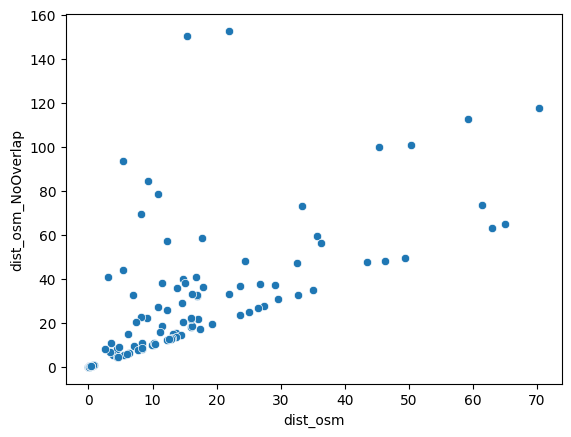

In [48]:
import seaborn as sns
sns.scatterplot(data=mk, x='dist_osm', y='dist_osm_NoOverlap')

## 2. districts

In [49]:
print("Joining markets to districts...")
d2 = gpd.read_file(os.path.join(REPO_DATA, 'ADM2_Dist_2024', 'ADM2_Dist_2024.shp'))
d2 = d2[['Pcode_24', 'Dist_ID_24', 'Prov_name', 'geometry']]
gp = gpd.GeoDataFrame(mk, geometry=gpd.points_from_xy(mk.marketlon, mk.marketlat), crs='EPSG:4326')
j = gpd.sjoin(gp, d2, how='left', predicate='within')
j = j[~j.index.duplicated(keep='first')]

mk['Pcode_24'] = j.Pcode_24.values
mk['Prov_ID'] = j.Prov_name.values
print(f"  {mk.Pcode_24.isna().sum()} unmatched; {mk.Pcode_24.nunique()} distinct districts")


Joining markets to districts...
  0 unmatched; 71 distinct districts


c:\Users\wb434633\.conda\envs\py310\lib\site-packages\pyogrio\raw.py:198: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D Polygon' is converted to 'Polygon Z'
  return ogr_read(


## 3. conflict

In [51]:
print("Building district-year conflict deaths...")
a = pd.read_csv(os.path.join(REPO_DATA, 'ACLED', 'ACLED_Conflict_Events.csv'), low_memory=False)
a['event_date'] = pd.to_datetime(a.event_date, format='mixed')
a['year'] = a.event_date.dt.year
a = a[a.sub_event_.isin(CHANNELS) & a.year.isin(YEARS)]
ag = gpd.GeoDataFrame(a, geometry=gpd.points_from_xy(a.longitude, a.latitude), crs='EPSG:4326')
aj = gpd.sjoin(ag, d2[['Pcode_24', 'geometry']], how='left', predicate='within')
aj = aj[~aj.index.duplicated(keep='first')].dropna(subset=['Pcode_24'])
deaths_dy = aj.groupby(['Pcode_24', 'year']).fatalities.sum().rename('deaths')

pop_path = next(p for p in [
    os.path.join(REPO_DATA, 'population', 'AFG_Population_Long_Format.csv'),
    os.path.join(DATA, 'population', 'AFG_Population_Long_Format.csv'),
] if os.path.exists(p))
pop = pd.read_csv(pop_path, encoding='utf-8-sig')
pw = (pop.groupby(['adm2_pcode', 'year'], as_index=False).population.sum()
        .rename(columns={'adm2_pcode': 'Pcode_24'}).set_index(['Pcode_24', 'year']).population)

dy = pd.DataFrame(index=pd.MultiIndex.from_product(
    [mk.Pcode_24.dropna().unique(), YEARS], names=['Pcode_24', 'year'])).reset_index()
dy['deaths'] = dy.set_index(['Pcode_24', 'year']).index.map(deaths_dy).fillna(0).to_numpy()
dy['population'] = dy.set_index(['Pcode_24', 'year']).index.map(pw).to_numpy()
dy['deaths_pc'] = 1e5 * dy.deaths / dy.population
dy['log_deaths_pc'] = np.log1p(dy.deaths_pc)
print(f"  district-years: {len(dy)}, missing population: {dy.population.isna().sum()}")

Building district-year conflict deaths...
  district-years: 568, missing population: 0


## 4. NDVI

In [52]:
print("Building growing-season (Q2) market-level NDVI deviation...")
ndvi_path = next(p for p in [
    os.path.join(REPO_DATA, 'ndvi', 'NDVI_markted.csv'),
    os.path.join(DATA, 'ndvi', 'NDVI_markted.csv'),
] if os.path.exists(p))
nd = pd.read_csv(ndvi_path, low_memory=False)
nd = nd[nd.quarter == 2].copy()
nd['ndvi_dev'] = (nd.ndvi_mean - nd.ndvi_mean_long_term) / nd.ndvi_std_long_term
ndvi_my = nd.set_index(['mktID', 'year']).ndvi_dev

Building growing-season (Q2) market-level NDVI deviation...


In [53]:
print("Building growing-season (Q2) district-level NDVI deviation...")


ndvi_dist = pd.read_csv(os.path.join(PROCESSED, "ndvi_district_quarterly.csv"))
ndvi_dist = ndvi_dist[ndvi_dist.quarter == 2].copy()
ndvi_dist = ndvi_dist[['district_id', 'year', 'quarter', 'ndvi_ag', 'ndvi_ag_dev', 'ndvi_ag_anom']].copy()


Building growing-season (Q2) district-level NDVI deviation...


## 5. outcomes

In [54]:
print("Market-year activity index (Model A outcome)...")
mm = market_year_activity(pnl)
idx = 100 * mm.div(mm[2020], axis=0)
act_long = idx.stack().rename('y_activity').reset_index().rename(columns={'level_1': 'year'})
act_long['y_activity'].describe()

act_long.groupby('year')['y_activity'].describe()

display(act_long[act_long['y_activity']>300])

a = idx.stack().to_frame().reset_index()
b = mm.reset_index()
mk_list = ['lon62_5018lat34_2416', 'lon64_1471lat30_8694',  'lon68_8661lat33_6955','lon64_7616lat31_9764', 'lon64_9931lat32_7535','lon65_61lat32_3537']
b[b['mktID'].isin(mk_list)]
# lon64_1471lat30_8694 lon68_8661lat33_6955 lon65_61lat32_3537	

Market-year activity index (Model A outcome)...


,mktID,year,y_activity


year,mktID,2017,2018,2019,2020,2021,2022,2023,2024,2025
11,lon62_5018lat34_2416,122.478705,135.813442,133.356644,129.677467,160.615663,158.838691,156.534464,154.472896,NaN
39,lon64_1471lat30_8694,NaN,142.278651,146.907817,136.273786,163.139790,NaN,131.367552,246.617771,NaN
76,lon64_7616lat31_9764,NaN,134.384927,133.709673,125.623285,109.658250,NaN,NaN,120.084228,87.277768
84,lon64_9931lat32_7535,NaN,81.607828,90.761811,90.033430,111.278754,NaN,NaN,116.774282,80.374069
93,lon65_61lat32_3537,NaN,117.162457,91.685815,195.630150,166.703420,178.032563,NaN,297.491575,138.781288
104,lon68_8661lat33_6955,NaN,160.463740,108.701591,162.699961,110.107642,NaN,NaN,NaN,NaN


In [55]:
print("Market-year activity index (Model A outcome)...")
mm = market_year_activity(pnl)
idx = 100 * mm.div(mm[2020], axis=0)
act_long = idx.stack().rename('y_activity').reset_index().rename(columns={'level_1': 'year'})

print("Nighttime lights (Model B outcome) from processed_data...")
bnr = pd.read_csv(os.path.join(PROCESSED, 'ntl_bnr_periodic137_8years.csv'), low_memory=False)
bnr = bnr.rename(columns={'orig_id': 'mktID'})
assert len(bnr) == 137 and bnr.mktID.is_unique
mean_cols = {y: sorted(c for c in bnr.columns if c.startswith(f'MEAN_BNR_{y}')) for y in YEARS}
for y in YEARS:
    assert len(mean_cols[y]) == 12, f"{y}: expected 12 monthly MEAN_BNR columns"

rows = []
for y in YEARS:
    mcols = mean_cols[y]
    feb_jun = [c for c in mcols if c[-2:] in ('02', '03', '04', '05', '06')]
    rows.append(pd.DataFrame({
        'mktID': bnr.mktID, 'year': y,
        'annual_mean_bnr': bnr[mcols].mean(axis=1).to_numpy(),
        'feb_jun_median_bnr': bnr[feb_jun].median(axis=1).to_numpy(),
    }))
ntl_my = pd.concat(rows, ignore_index=True)
ntl_my['log_feb_jun_bnr'] = np.log(ntl_my.feb_jun_median_bnr.where(ntl_my.feb_jun_median_bnr > 0))
print(f"  {(ntl_my.feb_jun_median_bnr <= 0).sum()} of {len(ntl_my)} market-years are dark")

always = ntl_my.groupby('mktID').annual_mean_bnr.apply(lambda s: (s > 0).all())
ever = ntl_my.groupby('mktID').annual_mean_bnr.apply(lambda s: (s > 0).any())
lit_markets = sorted(always[always].index)
ever_lit_markets = sorted(ever[ever].index)
print(f"  always-lit: {len(lit_markets)}   ever-lit: {len(ever_lit_markets)}")

Market-year activity index (Model A outcome)...
Nighttime lights (Model B outcome) from processed_data...
  0 of 1096 market-years are dark
  always-lit: 52   ever-lit: 107


## 6. assemble

In [56]:
# Add market classification
from config import (BASE, DATA, PROCESSED, OUTPUT, VIIRS_DIR, MASK_DIR,
                    KABUL_LON, KABUL_LAT, BUFFER_KM, MAX_RAD_CAP)

OUT_FIG = os.path.join(OUTPUT, "figures")
OUT_ES = os.path.join(OUTPUT, "event_study")
os.makedirs(OUT_FIG, exist_ok=True)
os.makedirs(OUT_ES, exist_ok=True)

MKT_ACCESS = os.path.join(BASE, "document", "Repo_09042026", "data", "derived", "mkt_access.csv")
DENS = {"low density": "Remote", "mid density": "Intermediate access", "high density": "High access"}
ACC_ORD = ["High access", "Intermediate access", "Remote"]
ACC_COL = {"High access": "#1baf7a", "Intermediate access": "#eb6834", "Remote": "#2a78d6"}

acc = pd.read_csv(MKT_ACCESS)
acc["access"] = acc.density.map(DENS)



In [57]:
# Travel times

df_travel = r"C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\data\Geospatial Analysis Outputs\afg_markets_points_accessibility_wp_and_GHSL.xlsx"
df_travel = pd.read_excel(df_travel)
df_travel = df_travel[['mktID', 'Threshold', 'TravelType', 'wp_SUM']].copy(deep=True)
df_travel = df_travel[df_travel['mktID'].isin(mk['mktID'].to_list())].copy(deep=True)

df_travel2 = r"C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\data\Geospatial Analysis Outputs\afg_missing_markets_points_accessibility_wp_and_GHSL.xlsx"
df_travel2 = pd.read_excel(df_travel2, sheet_name='ZonalSt_missing_markets_wp').rename(columns = {'SUM': 'wp_SUM'})
df_travel2 = df_travel2[['mktID', 'Threshold', 'TravelType', 'wp_SUM']].copy(deep=True)
df_travel2 = df_travel2[df_travel2['mktID'].isin(mk['mktID'].to_list())].copy(deep=True)

df_travel = pd.concat([df_travel, df_travel2], ignore_index=True)
    
len(df_travel['mktID'].unique())




137

In [58]:
df_wide = (df_travel
           .pivot_table(index='mktID', columns=['TravelType', 'Threshold'],
                        values='wp_SUM', aggfunc='first')
           .sort_index(axis=1))

# flatten the MultiIndex columns, e.g. "wp_SUM_foot_30"
df_wide.columns = [f"wp_SUM_{t}_{th}" for t, th in df_wide.columns]
df_wide = df_wide.reset_index()
df_wide.rename(columns={
    "wp_SUM_foot_30": "pop_30foot",
    "wp_SUM_foot_60": "pop_60foot",
    "wp_SUM_mixed_30": "pop_30mixed",
    "wp_SUM_mixed_60": "pop_60mixed"
}, inplace=True)

for col in ["pop_30foot", "pop_60foot", "pop_30mixed", "pop_60mixed"]:
    df_wide['ln_' + col] = np.log(df_wide[col].fillna(0) + 1)

df_wide.drop(columns=["pop_30foot", "pop_60foot", "pop_30mixed", "pop_60mixed"], inplace=True)
df_wide

,mktID,ln_pop_30foot,ln_pop_60foot,ln_pop_30mixed,ln_pop_60mixed
0,lon61_9514lat33_3139,8.220529,9.571662,10.485669,12.227679
1,lon62_1468lat34_2151,9.245576,10.424433,13.956623,14.335122
2,lon62_1746lat33_1658,8.579155,9.891150,11.260107,12.457897
3,lon62_1885lat32_6017,6.957085,8.169889,10.601612,12.887828
4,lon62_2258lat34_259,10.290360,11.371758,14.179306,14.416545
...,...,...,...,...,...
132,lon70_6402lat34_4017,9.137087,10.304488,13.333228,14.561681
133,lon70_7449lat34_2702,9.844559,10.702525,13.656313,14.572148
134,lon70_8026lat34_1925,9.727430,10.832856,13.137034,14.431754
135,lon70_8724lat34_6551,9.023124,10.400039,12.461949,14.090075


In [59]:
MKT_ACCESS = os.path.join(BASE, "document", "Repo_09042026", "data", "derived", "mkt_access.csv")
mkt_access = pd.read_csv(MKT_ACCESS, low_memory=False)


In [60]:
print("Assembling the long panel...")
panel = act_long.merge(mk[['mktID', 'once_a_week', 'dist_osm', 'dist_osm_NoOverlap', 'Pcode_24','Prov_ID',
                           'open_2018', 'open_2019', 'open_2020', 'open_2021', 'open_2022',
                           'open_2023', 'open_2024', 'open_2025']], on='mktID')
panel = panel.merge(dy[['Pcode_24', 'year', 'log_deaths_pc']], on=['Pcode_24', 'year'], how='left')

panel = panel.merge(mkt_access[['mktID', 'travel_50']], on='mktID', how='left')

panel = panel.merge(ndvi_my.reset_index(), on=['mktID', 'year'], how='left')
display(panel.shape)
panel = panel.merge(ndvi_dist.rename(columns={'district_id': 'Pcode_24'}), on=['year','Pcode_24'], how='left')
display(panel.shape)
panel = panel.merge(ntl_my, on=['mktID', 'year'], how='left')
panel = panel[panel.year.isin(YEARS)].copy()
panel = panel.merge(acc[['mktID', 'access']], on='mktID', how='left')
panel = panel.merge(df_wide[['mktID', 'ln_pop_30foot', 'ln_pop_60foot', 'ln_pop_30mixed', 'ln_pop_60mixed']], on='mktID', how='left')



panel['lit_market'] = panel.mktID.isin(lit_markets).astype('int8')
panel['ever_lit_market'] = panel.mktID.isin(ever_lit_markets).astype('int8')
panel['once_a_week'] = panel.once_a_week.astype('int8')
print(f"  panel: {panel.shape}, years {sorted(panel.year.unique())}")

panel.drop(columns=['annual_mean_bnr',], inplace=True)
panel.rename(columns={'feb_jun_median_bnr': 'light_emissions',
                      'log_feb_jun_bnr': 'log_light_emissions'}, inplace=True)

VAR_LABELS = {
    'mktID': 'Market ID',
    'year': 'Year',
    'y_activity': 'Market activity index (2020=100), each market rescaled to own 2020',
    'once_a_week': 'Once-a-week trading day indicator',
    'dist_osm': 'Distance to nearest OSM market (km)',
    'ln_pop_30foot': 'Log catchment population 30 minutes foot',
    'ln_pop_60foot': 'Log catchment population 60 minutes foot',
    'ln_pop_30mixed': 'Log catchment population 30 minutes mixed',
    'ln_pop_60mixed': 'Log catchment population 60 minutes mixed',
    'Pcode_24': 'District pcode (2024 boundaries)',
    'Prov_ID': 'Province ID',
    'log_deaths_pc': 'Log district deaths per 100,000 (district-year)',
    'ndvi_dev': 'Growing-season NDVI deviation (SD units) for the market catchment',
    'ndvi_ag': 'Growing-season NDVI for the district',
    'ndvi_ag_dev': 'Growing-season NDVI deviation (SD units) for the district',
    'ndvi_ag_anom': 'Growing-season NDVI for district: level minus long-run mean, NDVI units',
    'light_emissions': 'Median BNR-filtered radiance (10km buffer)',
    'log_light_emissions': 'Log of median BNR-filtered radiance (10km buffer)',
    'lit_market': 'In always-lit sample (positive BNR every year 2018-2025)',
    'ever_lit_market': 'In ever-lit sample (positive BNR in at least one year 2018-2025)',
    'travel_50': 'Travel time to nearest  50K town (minutes)',
}


dta = os.path.join(PROCESSED, 'event_study_panel.dta')

panel.to_stata(dta, write_index=False, variable_labels=VAR_LABELS, version=118)
# csv = os.path.join(PROCESSED, 'event_study_panel.csv')
# panel.to_csv(csv, index=False)
# print(f"wrote {csv}")

print(f"wrote {dta}")
print(panel.columns)
print("DONE")

Assembling the long panel...


(1085, 19)

(1085, 23)

  panel: (1084, 33), years [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
wrote C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\processed_data\event_study_panel.dta
Index(['mktID', 'year', 'y_activity', 'once_a_week', 'dist_osm',
       'dist_osm_NoOverlap', 'Pcode_24', 'Prov_ID', 'open_2018', 'open_2019',
       'open_2020', 'open_2021', 'open_2022', 'open_2023', 'open_2024',
       'open_2025', 'log_deaths_pc', 'travel_50', 'ndvi_dev', 'quarter',
       'ndvi_ag', 'ndvi_ag_dev', 'ndvi_ag_anom', 'light_emissions',
       'log_light_emissions', 'access', 'ln_pop_30foot', 'ln_pop_60foot',
       'ln_pop_30mixed', 'ln_pop_60mixed', 'lit_market', 'ever_lit_market'],
      dtype='object')
DONE


In [61]:
panel.columns

Index(['mktID', 'year', 'y_activity', 'once_a_week', 'dist_osm',
       'dist_osm_NoOverlap', 'Pcode_24', 'Prov_ID', 'open_2018', 'open_2019',
       'open_2020', 'open_2021', 'open_2022', 'open_2023', 'open_2024',
       'open_2025', 'log_deaths_pc', 'travel_50', 'ndvi_dev', 'quarter',
       'ndvi_ag', 'ndvi_ag_dev', 'ndvi_ag_anom', 'light_emissions',
       'log_light_emissions', 'access', 'ln_pop_30foot', 'ln_pop_60foot',
       'ln_pop_30mixed', 'ln_pop_60mixed', 'lit_market', 'ever_lit_market'],
      dtype='object')